# RandomUnderSampler
### <i>With a Regression Target </i>


### Imports

In [147]:
# pip install imblearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.under_sampling import RandomUnderSampler, ClusterCentroids
import warnings

warnings.filterwarnings("ignore")

# Loading the dataset
df = pd.read_csv("../../houses.csv")

# dropping unneeded columns before doing anything
df.drop(["id", "date", "lat", "long", 'zipcode'], axis=1, inplace=True)

df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
0,221900.00,3,1.00,1180,5650,1.00,0,0,3,7,1180,0,1955,0,1340,5650
1,538000.00,3,2.25,2570,7242,2.00,0,0,3,7,2170,400,1951,1991,1690,7639
2,180000.00,2,1.00,770,10000,1.00,0,0,3,6,770,0,1933,0,2720,8062
3,604000.00,4,3.00,1960,5000,1.00,0,0,5,7,1050,910,1965,0,1360,5000
4,510000.00,3,2.00,1680,8080,1.00,0,0,3,8,1680,0,1987,0,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.00,3,2.50,1530,1131,3.00,0,0,3,8,1530,0,2009,0,1530,1509
21609,400000.00,4,2.50,2310,5813,2.00,0,0,3,8,2310,0,2014,0,1830,7200
21610,402101.00,2,0.75,1020,1350,2.00,0,0,3,7,1020,0,2009,0,1020,2007
21611,400000.00,3,2.50,1600,2388,2.00,0,0,3,8,1600,0,2004,0,1410,1287


In [148]:
# since we can't really bin our target due to high amount of outliers
# we'll use a simple quantile to reduce them

# NOTE! if your dataset doesn't have this problem
# leave this part out
df.query("price <= price.quantile(0.99)", inplace=True)

<Axes: xlabel='price', ylabel='Count'>

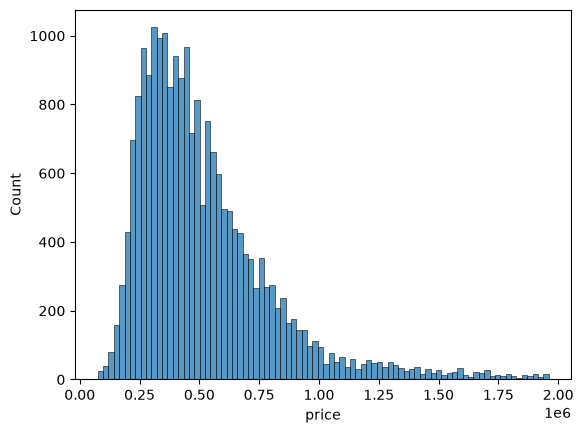

In [149]:
# Let's look at the distribution first to see what we're working with.
sns.histplot(df,x="price")

<Axes: xlabel='target_binned', ylabel='Count'>

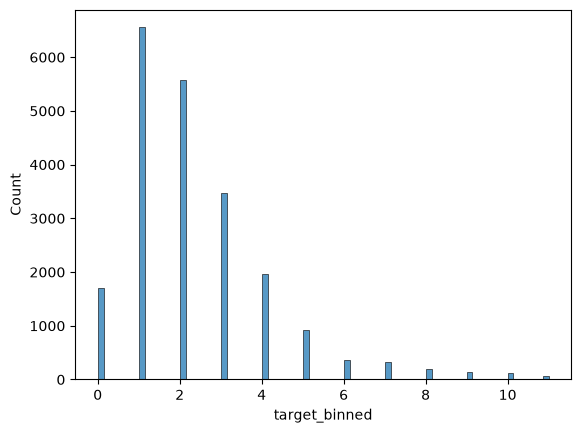

In [150]:
# Create 12 bins of price. 
target = "price"

# create temporary categories based on our regression target => binning
df['target_binned'] = pd.cut(df[target], bins=12, labels=False)

# That looks like so.
sns.histplot(df, x="target_binned")

In [151]:
# This is really helpful to help you set the 'strategy' parameter in Undersampling.
# NOTE: This assumes your dataframe is called `df`

# Insert your column name here
column_name = "target_binned"

# Extract the unique values
column = df[column_name]
unique_values = column.unique()

# For each unique value, print the count.
for unique_value in unique_values:
    count = (column == unique_value).sum()
    print(unique_value,":", count)

# Now we know our upper limits when setting the strategy.

0 : 1704
2 : 5571
3 : 3476
7 : 328
1 : 6553
5 : 928
4 : 1957
8 : 190
6 : 368
9 : 132
11 : 73
10 : 116


In [152]:
# X, y split
X = df.drop('target_binned', axis=1)
y = df['target_binned']

# Set the strategy to tailor our needs. In this case
# Say we did some extensive research into this data
# and it's more realistic that all the diamonds have
# a normally distributed price. Let's make it look 
# that way instead.

# NOTE! your values have to match with original distribution
# you can't have more data in a target bin that was already there
# in the case of undersampling! 
strategy = {
    0 : 1704,
    1 : 4553,
    2 : 4571,
    3 : 3476,
    4 : 1957,
    5 : 928,
    6 : 368,
    7 : 328,
    8 : 190,
    9 : 132,
    10 : 116,
    11 : 73
}


# Let's create the sampler object. 
sampler = RandomUnderSampler(sampling_strategy=strategy, random_state=321)

# if you just try with the default RandomUnderSampled
# you pretty much lose most of the data
# and the distribution is a weird even distribution
# but the highest prices are emphasized
# sampler = RandomUnderSampler(random_state=321)

# Use the sampler.
X_resampled, y_resampled = sampler.fit_resample(X, y)

# Put the dataframe back together after sampling.
df_resampled_rus = pd.DataFrame(X_resampled, columns=X.columns)

# if you still need the binned target for regression
# you can use this, but you can also leave it out
df_resampled_rus['target_binned'] = y_resampled

<Axes: xlabel='target_binned', ylabel='Count'>

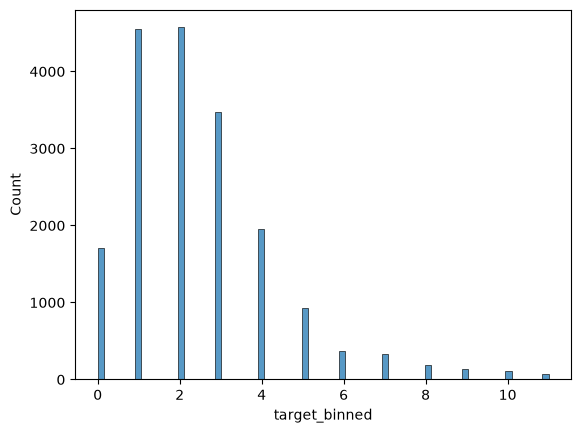

In [153]:
sns.histplot(df_resampled_rus, x="target_binned")

In [154]:
# Check the amount of rows.
df_resampled_rus.shape

# We shaved OFF a metric ton of rows here. It's always good to keep in mind
# 1. That you're reflecting reality/population
# 2. You have enough rows to feed a ML model 

(18396, 17)

In [155]:
df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15,target_binned
0,221900.00,3,1.00,1180,5650,1.00,0,0,3,7,1180,0,1955,0,1340,5650,0
1,538000.00,3,2.25,2570,7242,2.00,0,0,3,7,2170,400,1951,1991,1690,7639,2
2,180000.00,2,1.00,770,10000,1.00,0,0,3,6,770,0,1933,0,2720,8062,0
3,604000.00,4,3.00,1960,5000,1.00,0,0,5,7,1050,910,1965,0,1360,5000,3
4,510000.00,3,2.00,1680,8080,1.00,0,0,3,8,1680,0,1987,0,1800,7503,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.00,3,2.50,1530,1131,3.00,0,0,3,8,1530,0,2009,0,1530,1509,1
21609,400000.00,4,2.50,2310,5813,2.00,0,0,3,8,2310,0,2014,0,1830,7200,2
21610,402101.00,2,0.75,1020,1350,2.00,0,0,3,7,1020,0,2009,0,1020,2007,2
21611,400000.00,3,2.50,1600,2388,2.00,0,0,3,8,1600,0,2004,0,1410,1287,2


In [156]:
df_resampled_rus

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15,target_binned
1243,170000.00,3,1.50,1350,81549,1.00,0,0,2,7,1350,0,1966,0,2220,93825,0
3265,218000.00,3,2.25,1610,7084,1.00,0,0,4,8,1280,330,1968,0,2170,8505,0
1996,194000.00,3,1.50,1010,5000,1.00,0,0,3,6,1010,0,1943,0,980,5000,0
7117,215000.00,3,1.50,1240,9405,1.00,0,0,4,7,1240,0,1966,0,2260,7611,0
16353,201000.00,3,1.00,900,7576,1.00,0,0,4,6,900,0,1959,0,1220,7452,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9414,1925000.00,5,4.25,4830,8050,2.50,0,2,4,11,3710,1120,1914,0,4470,9194,11
5749,1850000.00,4,2.50,3830,11972,1.00,1,4,3,11,2370,1460,1981,0,3080,12297,11
7886,1900000.00,4,2.25,3020,11489,1.50,1,3,5,10,2110,910,1916,1988,3890,11489,11
12459,1900000.00,6,4.00,3020,13237,2.00,1,4,3,8,2840,180,1942,1983,3680,12620,11


In [157]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

In [158]:
# Comparing the two statistically
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15,target_binned
count,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00,21396.00
mean,518115.33,3.36,2.10,2050.49,14993.24,1.49,0.01,0.22,3.41,7.63,1766.21,284.28,1970.99,82.27,1971.61,12696.71,2.33
std,284587.46,0.92,0.75,861.41,40979.49,0.54,0.07,0.73,0.65,1.14,791.59,430.40,29.31,396.79,668.10,27203.76,1.83
min,75000.00,0.00,0.00,290.00,520.00,1.00,0.00,0.00,1.00,1.00,290.00,0.00,1900.00,0.00,399.00,651.00,0.00
25%,320000.00,3.00,1.50,1420.00,5026.00,1.00,0.00,0.00,3.00,7.00,1190.00,0.00,1951.75,0.00,1480.00,5100.00,1.00
50%,450000.00,3.00,2.25,1900.00,7575.50,1.50,0.00,0.00,3.00,7.00,1550.00,0.00,1975.00,0.00,1830.00,7600.00,2.00
75%,635000.00,4.00,2.50,2520.00,10548.50,2.00,0.00,0.00,4.00,8.00,2190.00,550.00,1997.00,0.00,2340.00,10021.25,3.00
max,1960000.00,33.00,7.50,7730.00,1651359.00,3.50,1.00,4.00,5.00,13.00,7420.00,3260.00,2015.00,2015.00,5790.00,871200.00,11.00


In [ ]:
# fairly similar results, except price due to binning probably
df_resampled_rus.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15,target_binned
count,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00,18396.00
mean,543550.57,3.39,2.13,2100.88,15336.26,1.50,0.01,0.24,3.41,7.69,1806.64,294.25,1970.82,86.26,2009.17,12902.70,2.49
std,297341.01,0.93,0.76,889.58,42476.67,0.54,0.08,0.76,0.65,1.17,817.68,439.98,29.58,405.91,690.36,27595.50,1.91
min,75000.00,0.00,0.00,290.00,520.00,1.00,0.00,0.00,1.00,1.00,290.00,0.00,1900.00,0.00,399.00,659.00,0.00
25%,331000.00,3.00,1.75,1440.00,5024.00,1.00,0.00,0.00,3.00,7.00,1200.00,0.00,1951.00,0.00,1500.00,5090.75,1.00
50%,480000.00,3.00,2.25,1960.00,7599.50,1.50,0.00,0.00,3.00,8.00,1590.00,0.00,1975.00,0.00,1870.00,7620.00,2.00
75%,675000.00,4.00,2.50,2610.00,10690.50,2.00,0.00,0.00,4.00,8.00,2260.00,570.00,1997.00,0.00,2406.75,10125.00,3.00
max,1960000.00,33.00,7.50,7730.00,1651359.00,3.50,1.00,4.00,5.00,13.00,7420.00,3260.00,2015.00,2015.00,5790.00,871200.00,11.00


---

Quite decent results with this undersampling (but only 3000 was dropped)

In [ ]:
# let's see the variances too
df.var(numeric_only=True)

price           80990024180.18
bedrooms                  0.85
bathrooms                 0.56
sqft_living          742021.80
sqft_lot         1679318274.11
floors                    0.29
waterfront                0.01
view                      0.53
condition                 0.42
grade                     1.29
sqft_above           626618.96
sqft_basement        185245.03
yr_built                858.92
yr_renovated         157445.31
sqft_living15        446352.54
sqft_lot15        740044784.72
target_binned             3.34
dtype: float64

In [ ]:
# fairly similar
df_resampled_rus.var(numeric_only=True)

price           88411677303.34
bedrooms                  0.87
bathrooms                 0.58
sqft_living          791345.46
sqft_lot         1804267716.49
floors                    0.29
waterfront                0.01
view                      0.58
condition                 0.43
grade                     1.37
sqft_above           668598.45
sqft_basement        193584.48
yr_built                874.85
yr_renovated         164761.57
sqft_living15        476596.59
sqft_lot15        761511697.81
target_binned             3.66
dtype: float64